# 02 · Cleaning `daily` and `annual_indices`

**Goal:** turn the two main subsets of the training data into a processed dataset for model training.
For every problem this notebook gives: **what** it is, **why** it matters for the forecast, **how** it is
detected, the **action** taken, and the **evidence** that the action is right.

**Scope:** `daily` (one row per city and day) and `annual_indices` (one row per city and year). The other two
subsets are used only as look-ups: station start dates (from `city_info`) for the station-change step, and
city coordinates for finding neighbours. Challenge data only (weather up to 2018-12-31).

**Where the code lives:** all logic is in [`meet_cleaning.py`](meet_cleaning.py) next to this notebook. This
notebook runs it step by step and shows the evidence. The same files can be rebuilt without the notebook:
`uv run python notebooks/Meet/meet_cleaning.py`. Every threshold is a named constant at the top of that file.

### Three rules behind every decision

1. **Targets keep the official definition.** The 2019–2025 answers will be computed from raw station data
   with the 10-day rule. Training targets must mean the same thing, so they are only recomputed from cleaned
   days with that rule, never filled or adjusted. Filling and adjusting create separate **input** columns.
2. **Delete only with evidence.** A reading is deleted when it is physically impossible, or when the city's own
   days before and after *and* its neighbours all disagree with it. A strange reading is not enough.
3. **Every decision is on record.** Deletions go to `qc_log.csv`; the outlier review lives in a tracked CSV that a
   person can edit; the code applies it. Nothing is changed by hand in the data.

### The pipeline

| Step | Table | Problem | Action | Changes the targets? |
|---|---|---|---|---|
| D1 | daily | Duplicate keys, missing calendar days | Check; stop if broken | – |
| D2 | daily | Impossible values (tmax < tmin, beyond U.S. records) | Delete | Yes (9 days) |
| D3 | daily | Stuck sensors, repeated rain values | Delete stuck runs the neighbours contradict | Yes (5 runs, 1900s) |
| D4 | daily | Outliers | Keep if a neighbour confirms; delete isolated one-day spikes far from neighbours; review file | Yes (1 reading) |
| D5 | daily → annual | Rebuild the yearly table | Verify against the published table, then recompute from cleaned days | Recomputed, official rule |
| D6 | daily | Years with 11–30 missing days read low | Fill missing days: city normal + neighbours' anomaly | No: input columns |
| A1 | annual | ±∞ sentinels, fake zeros, partial years | NaN; 10-day validity rule per column | Official rule |
| A2 | annual | Detached early record fragments | Delete | Removes rows |
| A3 | annual | Station changes shift the level | Measure each step against neighbours; shift old segments | No: input columns |
| A4 | annual | Empty years | Fill from neighbours' values that year + usual difference | No: input columns |
| E | – | Which input variants help a forecast? | Rolling-origin backtest, rule fixed below | – |
| F | – | Write the processed files | `data/processed/meet/` | – |

## 0. Setup

Works locally and on **Google Colab** (the first cell clones the public repo when it is not already there;
Colab only sees what is pushed to GitHub). Raw data are read from `data/raw/` if downloaded, otherwise streamed
from the Hugging Face Hub at the pinned revision. Every weather table passes `assert_no_post_cutoff()`.
Memory: about 3 GB at peak.

In [1]:
# Find the repo, or clone it (Colab / fresh machine)
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/Meet2304/ProtoStar-Challenge.git"
BRANCH = "Meet_Exploration"


def find_repo_root():
    return next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "code" / "common.py").exists()), None)


ROOT = find_repo_root()
if ROOT is None:
    ROOT = Path("/content/ProtoStar-Challenge") if "google.colab" in sys.modules else Path.cwd() / "ProtoStar-Challenge"
    if (ROOT / ".git").exists():
        subprocess.run(["git", "-C", str(ROOT), "pull", "-q"], check=False)
    elif subprocess.run(["git", "clone", "-q", "--branch", BRANCH, REPO_URL, str(ROOT)]).returncode != 0:
        print(f"Branch {BRANCH!r} not on GitHub yet: cloning the default branch instead.")
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    os.chdir(ROOT)
print("Repo root:", ROOT)

Repo root: <repository root>


In [2]:
import importlib
import logging
import time
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

sys.path.insert(0, str(ROOT / "code"))
sys.path.insert(0, str(ROOT / "notebooks" / "Meet"))
import combo_model as cm
import meet_cleaning as mc
from common import METRICS, load_valid_annual, wide
importlib.reload(mc)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
warnings.filterwarnings("ignore", category=RuntimeWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
KEEP, DELETE, CONFIRMED = SERIES[2], SERIES[7], SERIES[0]
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 90, "font.size": 10, "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "lines.markersize": 4, "legend.frameon": False,
    "axes.prop_cycle": mpl.cycler(color=SERIES),
})

The next cell runs steps D1–D4 and A2 once (about one minute): it loads `daily`, runs every check, writes the
outlier review file `notebooks/Meet/qc/daily_outlier_decisions.csv` (keeping any edits already in it) and deletes
the readings the rules mark. The sections after it show what each step found and why it acted as it did.

In [3]:
t0 = time.time()
P = mc.prepare(keep_raw=True)          # D1-D4, A2 (see meet_cleaning.prepare)
W_raw, W = P["W_raw"], P["W_clean"]    # {var: Date x city table}, before / after cleaning
NAME = P["cities"]["name"]
nm = lambda ids: NAME.reindex(ids).to_numpy()   # noqa: E731
print(f"prepared in {time.time() - t0:.0f} s; daily tables {W['tmax'].shape} (days x cities)")

D2 impossible values ...


D3 stuck sensors ...


D4 outliers ...


A2 record fragments ...


prepared in 55 s; daily tables (61361, 210) (days x cities)


# Part 1 · `daily`

## D1. Structure

**What:** check that every (city, day) appears exactly once, that no day is missing from the calendar inside a
record, and that nothing is dated after 2018-12-31.
**Why:** every later step (runs of identical values, the day before and after, neighbours on the same day) assumes
one row per city per day. A duplicated or skipped day would make those comparisons wrong without any error.
**Action:** none needed if the checks pass; the code stops otherwise.

,value
rows,10245754
cities,210
first date,1851-01-01
last date,2018-12-31
"duplicate (city, date) keys",0
cities with missing calendar days,0
"days with no value at all (row present, all NaN)",416164
records starting on 1 Jan,210
records ending 2018-12-31,210


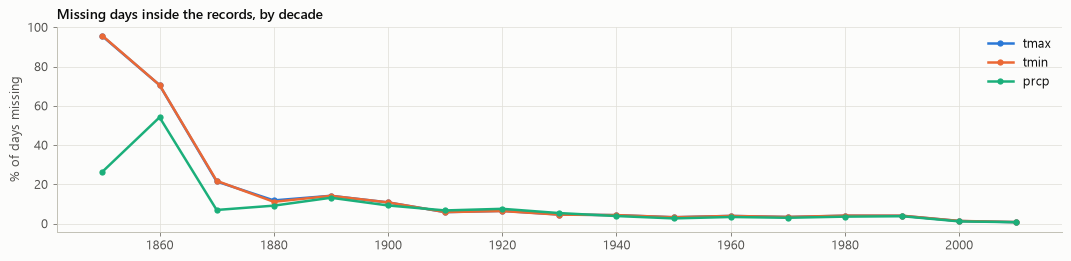

In [4]:
display(P["checks"])
# How much of each variable is missing, by decade, inside the records
rec = P["record_raw"]                                        # days inside a record (before A2)
dec = (W_raw["tmax"].index.year // 10) * 10
miss = pd.DataFrame({v: (W_raw[v].isna() & rec).groupby(dec).sum().sum(axis=1) / rec.groupby(dec).sum().sum(axis=1) * 100
                     for v in mc.VARS})
fig, ax = plt.subplots(figsize=(12, 3))
for i, v in enumerate(mc.VARS):
    ax.plot(miss.index, miss[v], marker="o", color=SERIES[i], label=v)
ax.set_ylabel("% of days missing"); ax.set_title("Missing days inside the records, by decade"); ax.legend()
plt.tight_layout(); plt.show()

**Result:** 10,245,754 rows, 210 cities, no duplicate keys, no gaps in any calendar, every record starts on 1 January
and ends on 2018-12-31. Missing values are rows with NaN: 416,164 days have no value at all. Missing data are
common before 1900 and in the 1940s–50s for some cities, and rare after 1990. So the structure is sound; the
problems are in the values.

## D2. Impossible values

**What:** readings that cannot be right: a daily maximum below the daily minimum, or values beyond the
contiguous-U.S. records (tmax > 134 °F, tmin < −70 °F, rain < 0 or > 43 in in a day).
**Why:** they enter the yearly means and, for tmax, can become the hottest day of the year (a target).
**Action: delete.** For tmax < tmin, one of the two values is wrong but the data cannot tell which, so **both
temperatures of that day are deleted**; precipitation is kept.

In [5]:
limits = pd.Series({
    "tmax > 134 °F": int((W_raw["tmax"] > mc.TMAX_LIMIT).sum().sum()),
    "tmin < -70 °F": int((W_raw["tmin"] < mc.TMIN_LIMIT).sum().sum()),
    "prcp < 0": int((W_raw["prcp"] < 0).sum().sum()),
    "prcp > 43 in": int((W_raw["prcp"] > mc.PRCP_LIMIT).sum().sum()),
    "tmax < tmin": int((W_raw["tmax"] < W_raw["tmin"]).sum().sum()),
}, name="days").to_frame()
display(limits)
imp = P["impossible"].pivot_table(index=["city_id", "date"], columns="var", values="value").reset_index()
imp.insert(1, "name", nm(imp["city_id"]))
imp

,days
tmax > 134 °F,0
tmin < -70 °F,0
prcp < 0,0
prcp > 43 in,0
tmax < tmin,9


var,city_id,name,date,tmax,tmin
0,USC00356749,Portland,1999-12-13,51.000,53.000
1,USW00013895,Montgomery,1917-09-06,71.000,72.000
2,USW00014847,SaultSteMarie,1889-02-04,15.000,16.000
3,USW00014847,SaultSteMarie,1899-08-18,55.000,59.000
4,USW00014897,Wausau,1918-08-06,61.000,66.000
5,USW00094014,Williston,1896-02-29,4.000,10.000
6,USW00094014,Williston,1930-01-16,-29.000,-28.000
7,USW00094014,Williston,1946-01-31,-17.000,-6.000
8,USW00094850,Marquette,1882-12-22,37.000,38.000


**Result:** no reading breaks a physical limit. Nine days have tmax below tmin, eight of them before 1950, and
one since 1989 (Portland, 1999-12-13: 51 / 53 °F). Deleting 18 values out of about 19 million temperature
readings moves no yearly mean by more than a few hundredths of a degree, so the action is safe.

## D3. Sensor faults

### Stuck temperature sensors

**What:** a sensor (or a copy error) that repeats one value day after day.
**Why:** a stuck value replaces real weather. If the stuck value is high it can set the hottest day; over a
week it shifts the yearly mean.
**How:** find every run of ≥ 7 identical tmax or tmin values. A long identical run alone is not evidence:
steady climates (a Gulf Coast summer at 91 °F) produce them naturally. The test is whether **the weather
nearby kept changing**: the median, over the 3 nearest cities, of their standard deviation during the run.
**Action:** if the neighbours varied by ≥ 5 °F, delete the run after its first day (the first reading may be
real); otherwise keep.

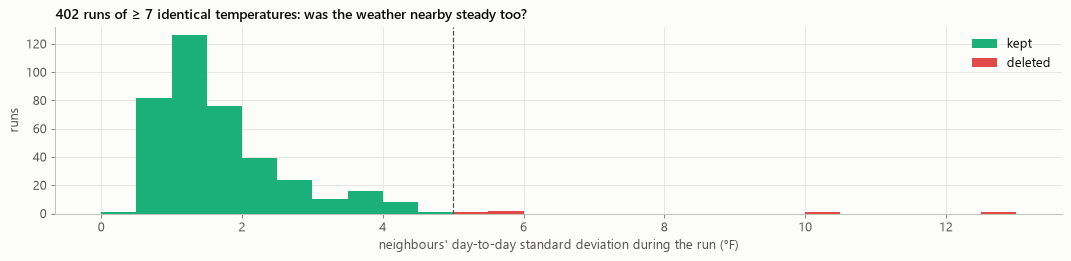

Runs by era: {'before 1989': 328, '1989+': 74}


,name,var,start,end,days,value,neighbour_sd
36,Missoula,tmax,1903-03-10,1903-03-22,13,55.000,12.537
230,Scottsbluff,tmin,1902-06-03,1902-06-10,8,43.000,5.975
232,Missoula,tmin,1903-03-09,1903-03-22,14,15.000,10.472
240,Astoria,tmin,1904-12-05,1904-12-11,7,36.000,5.563
286,Morgantown,tmin,1931-11-26,1931-12-02,7,29.000,5.469


In [6]:
runs = P["stuck"].assign(name=lambda x: nm(x["city_id"]))
fig, ax = plt.subplots(figsize=(12, 3))
bins = np.arange(0, 13.5, 0.5)
ax.hist(runs.loc[runs["action"] == "keep", "neighbour_sd"], bins=bins, color=KEEP, label="kept")
ax.hist(runs.loc[runs["action"] == "delete", "neighbour_sd"], bins=bins, color=DELETE, label="deleted")
ax.axvline(mc.STUCK_NEIGHBOUR_SD, color=INK2, lw=1, ls="--")
ax.set_xlabel("neighbours' day-to-day standard deviation during the run (°F)"); ax.set_ylabel("runs")
ax.set_title(f"{len(runs)} runs of ≥ {mc.STUCK_MIN_DAYS} identical temperatures: was the weather nearby steady too?")
ax.legend(); plt.tight_layout(); plt.show()
print("Runs by era:", runs.groupby(runs["start"].dt.year >= 1989).size().rename({False: "before 1989", True: "1989+"}).to_dict())
runs[runs["action"] == "delete"][["name", "var", "start", "end", "days", "value", "neighbour_sd"]]

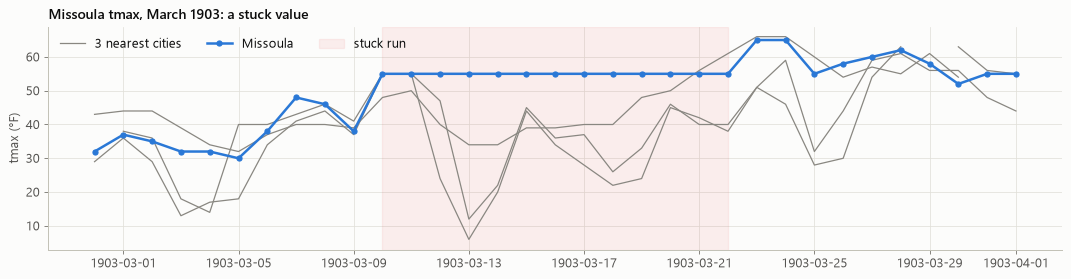

In [7]:
# Example: Missoula, March 1903 (tmax stuck at 55 °F for 13 days while neighbours swung by 12 °F)
ex = runs.sort_values("neighbour_sd", ascending=False).iloc[0]
win = slice(ex["start"] - pd.Timedelta(days=10), ex["end"] + pd.Timedelta(days=10))
fig, ax = plt.subplots(figsize=(12, 3.2))
for i, nb in enumerate(P["nbrs"][ex["city_id"]]):
    ax.plot(W_raw[ex["var"]].loc[win, nb], color=MUTED, lw=1, label="3 nearest cities" if i == 0 else None)
ax.plot(W_raw[ex["var"]].loc[win, ex["city_id"]], color=SERIES[0], marker="o", label=ex["name"])
ax.axvspan(ex["start"], ex["end"], color=DELETE, alpha=0.08, label="stuck run")
ax.set_ylabel(f"{ex['var']} (°F)"); ax.set_title(f"{ex['name']} {ex['var']}, {ex['start']:%B %Y}: a stuck value"); ax.legend(ncol=3)
plt.tight_layout(); plt.show()

**Result:** 402 runs; for almost all of them the neighbours were as steady as the city (median spread 1.4 °F),
so they are real steady weather and are kept. Five runs, all before 1935, were flat while the neighbours swung
by 5.5–12.5 °F: Missoula March 1903 (both tmax and tmin), Scottsbluff 1902, Astoria 1904 and Morgantown 1931.
They are deleted (44 readings). None fall in 1989–2018, so the training window is not affected.

### Repeated rain values

**What:** three or more consecutive wet days with exactly the same amount (e.g. 0.62 in for 5 days).
**Why it looks wrong:** real rain rarely repeats exactly. The usual cause is an observer who recorded a
multi-day total and the archive spreading it evenly over the days.
**Action: keep.** An evenly spread total leaves the **yearly total (the target) unchanged**; only the
1-day maximum (an input) is affected. Most repeated values are tiny (0.01–0.05 in, drizzle or trace days),
where repetition is natural.

In [8]:
rp = P["repeated_prcp"]
print(f"{len(rp)} runs, {rp['days'].sum()} days in total")
display(rp.groupby(pd.cut(rp["value"], [0, 0.01, 0.05, 0.1, 0.5, 1, 30])).agg(runs=("days", "size"), days=("days", "sum")).T)
rp.sort_values("value", ascending=False).head(5).assign(name=lambda x: nm(x["city_id"]))

1566 runs, 4853 days in total


value,"(0.0, 0.01]","(0.01, 0.05]","(0.05, 0.1]","(0.1, 0.5]","(0.5, 1.0]"
runs,875,502,98,84,7
days,2728,1536,308,258,23


,city_id,start,end,days,value,action,name
24,USW00014745,1875-08-03,1875-08-05,3,0.760,keep,Concord
178,USW00024213,1894-01-16,1894-01-18,3,0.700,keep,Eureka
139,USW00012844,1889-02-20,1889-02-22,3,0.620,keep,WestPalmBeach
0,USW00014745,1868-05-20,1868-05-24,5,0.620,keep,Concord
352,USW00003872,1910-04-21,1910-04-23,3,0.600,keep,Beckley


## D4. Outliers

The step the decision matters most for: an extreme reading is either the most important weather of the
year or an error. Deleting real extremes would make the hottest-day target read low; keeping errors would
make it read high.

### How a reading becomes a candidate

**Robust z-score** within each city and calendar month, over all years:
`z = (x − median) / (1.4826 × MAD)` (MAD = median absolute deviation). The median and MAD replace the mean and
standard deviation so the outliers being looked for do not widen the yardstick. Every tmax or tmin with
|z| > 5 is a candidate.

### What decides it

| Evidence | Meaning |
|---|---|
| `nb_support` | The most unusual same-sign z among the 3 nearest cities, that day or ±1 day. ≥ 2.5 means a nearby city saw the same event: **confirmed**. |
| `spike` | The reading jumps ≥ 3 z-units from both the nearest reading before and after (within 3 days, so a missing day next to it does not hide a spike): a one-day event in the city's own record. |
| `n_nb` | How many of the 3 nearest cities had a reading that day. |
| `nb_z`, `resid_z`, `resid_f` | The neighbours' average z that day, and how far the reading is from what that implies, in z units and in °F. |

### The rule (applied in this order)

1. **Confirmed by a neighbour → keep.** A cold outbreak or heat wave shows up in more than one city.
2. **Isolated + one-day spike + ≥ 5 z-units *and* ≥ 25 °F from what the neighbours imply + at least 2
   neighbours had a reading that day → delete.** Nobody nearby saw it, and the city itself was normal the day
   before and after: the signature of a keying error.
3. **Anything else → keep.** An isolated event that lasts more than a day is weather (a sensor that is wrong
   for days is the stuck-run case in D3). An isolated spike within 25 °F of what the neighbours imply is
   plausible weather too.

**Why both a z and a °F test:** in steady coastal climates (Eureka, San Diego, Astoria) the spread is so small
that a real one-day offshore-wind heat event reaches z = 7–8 while being only 15–22 °F above normal. Several
of them are that year's hottest day. A z-only rule would have deleted 42 readings, including those real hottest
days. The °F test keeps them.

**Why the neighbour-data test:** before 1900 many readings are "isolated" only because the neighbours had no
data that day (e.g. Spokane −30 °F and Boise −28 °F in the January 1888 cold wave). Missing neighbours are
no evidence against a reading.

In [9]:
cand = P["candidates"].assign(name=lambda x: nm(x["city_id"]), era=lambda x: np.where(x["date"].dt.year >= 1989, "1989-2018", "before 1989"))
summary = cand.pivot_table(index=["var", "class"], columns="era", values="z", aggfunc="size", fill_value=0)
summary["total"] = summary.sum(axis=1)
display(summary)
print("Proposed actions:", cand["proposed_action"].value_counts().to_dict())
print(f"Confirmed share: {(cand['class'] == 'confirmed by neighbours').mean():.1%}")

era                           1989-2018  before 1989  total
var  class                                                 
tmax confirmed by neighbours        308         1258   1566
     isolated                        33          239    272
tmin confirmed by neighbours        343         1852   2195
     isolated                        16          136    152

Proposed actions: {'keep': 4184, 'delete': 1}
Confirmed share: 89.9%


### All outliers in two pictures

Left: every candidate. Most sit above the dashed line: a nearby city was also unusual, so they are real.
Right: only the isolated ones, placed by how far they are from what the neighbours imply. Only readings in
the top-right box that are also one-day spikes are deleted.

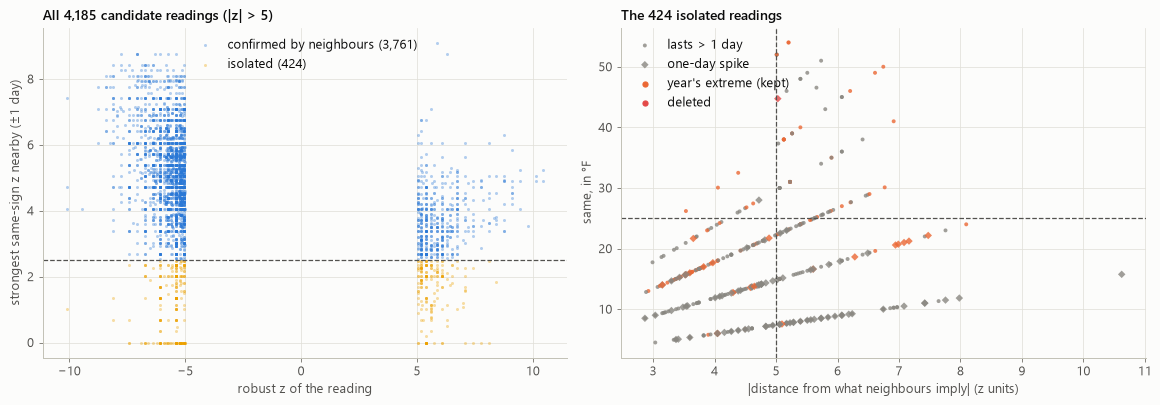

In [10]:
iso = cand[cand["class"] == "isolated"]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axs[0]
for cls, col in [("confirmed by neighbours", CONFIRMED), ("isolated", SERIES[3])]:
    s = cand[cand["class"] == cls]
    ax.scatter(s["z"], s["nb_support"], s=6, alpha=0.35, color=col, label=f"{cls} ({len(s):,})", lw=0)
ax.axhline(mc.Z_SUPPORT, color=INK2, lw=1, ls="--")
ax.set_xlabel("robust z of the reading"); ax.set_ylabel("strongest same-sign z nearby (±1 day)")
ax.set_title(f"All {len(cand):,} candidate readings (|z| > {mc.Z_CANDIDATE:g})"); ax.legend(loc="upper center")
ax = axs[1]
for spike, mk, lab in [(False, "o", "lasts > 1 day"), (True, "D", "one-day spike")]:
    s = iso[iso["spike"] == spike]
    col = np.where(s["proposed_action"] == "delete", DELETE, np.where(s["year_extreme"], SERIES[1], MUTED))
    ax.scatter(s["resid_z"].abs(), s["resid_f"].abs(), c=col, marker=mk, s=18 if spike else 10, alpha=0.8, lw=0, label=lab)
ax.axvline(mc.RESID_Z_DELETE, color=INK2, lw=1, ls="--"); ax.axhline(mc.RESID_F_DELETE, color=INK2, lw=1, ls="--")
ax.set_xlabel("|distance from what neighbours imply| (z units)"); ax.set_ylabel("same, in °F")
ax.set_title(f"The {len(iso)} isolated readings")
ax.scatter([], [], color=SERIES[1], label="year's extreme (kept)"); ax.scatter([], [], color=DELETE, label="deleted")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

### Every isolated reading since 1989, one panel each

Each panel shows 31 days around the reading: the city (blue), its 3 nearest cities (gray), the city's normal
band for that month (median ± 2 robust SDs) and the reading itself (red = deleted, orange = kept and the
year's extreme, green = kept). These are the readings a person should look at; confirmed ones need no review.

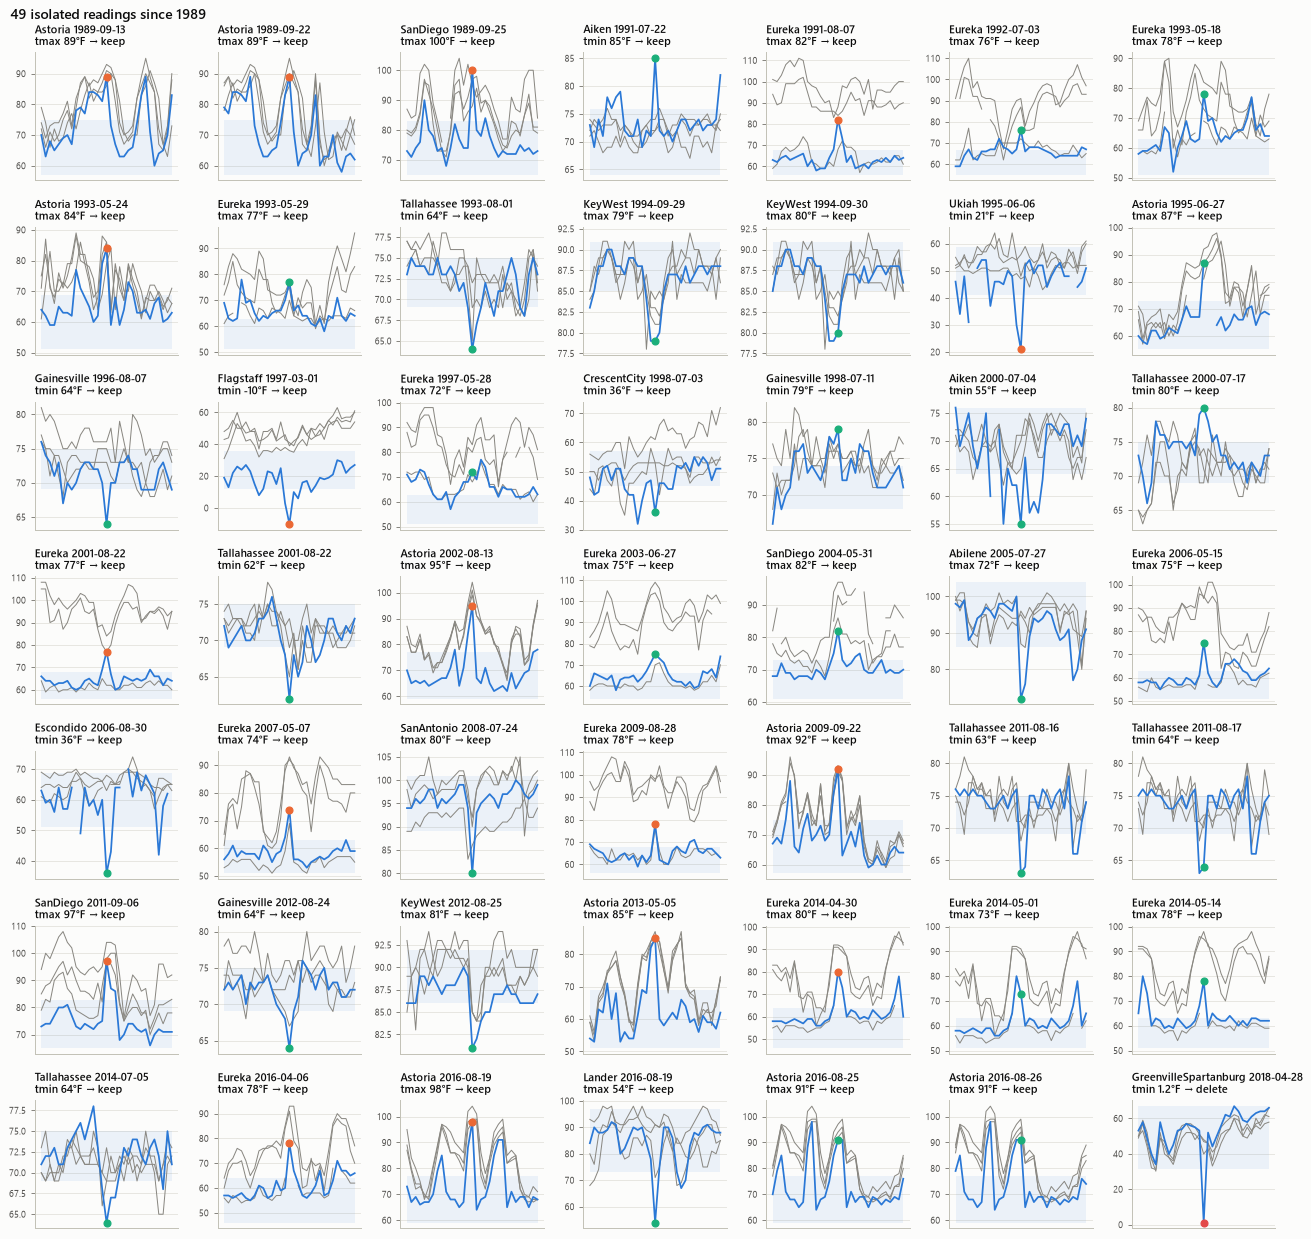

In [11]:
def plot_candidate(ax, r, days=15):
    var, city, date = r["var"], r["city_id"], pd.Timestamp(r["date"])
    win = slice(date - pd.Timedelta(days=days), date + pd.Timedelta(days=days))
    M = W_raw[var]
    for nb in P["nbrs"][city]:
        ax.plot(M.loc[win, nb], color=MUTED, lw=0.8)
    s = M.loc[win, city]
    ax.fill_between(s.index, r["median"] - 2 * r["scale"], r["median"] + 2 * r["scale"], color=SERIES[0], alpha=0.08, lw=0)
    ax.plot(s, color=SERIES[0], lw=1.4)
    col = DELETE if r["proposed_action"] == "delete" else (SERIES[1] if r["year_extreme"] else KEEP)
    ax.scatter([date], [r["value"]], color=col, s=30, zorder=5)
    ax.set_title(f"{NAME[city]} {date:%Y-%m-%d}\n{var} {r['value']:g}°F → {r['proposed_action']}", fontsize=8.5)
    ax.tick_params(labelsize=7); ax.set_xticks([])


def gallery(rows, ncol=7, title=None):
    n = len(rows)
    nrow = int(np.ceil(n / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(2.05 * ncol, 2.0 * nrow), squeeze=False)
    for ax, (_, r) in zip(axs.flat, rows.iterrows()):
        plot_candidate(ax, r)
    for ax in axs.flat[n:]:
        ax.axis("off")
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=11, fontweight="semibold")
    plt.tight_layout()
    return fig


recent = iso[iso["date"].dt.year >= 1989].sort_values("date")
gallery(recent, title=f"{len(recent)} isolated readings since 1989"); plt.show()

In [12]:
# All isolated readings (every era) as PNG pages, for browsing outside the notebook (git-ignored)
plot_dir = mc.OUT_DIR / "outlier_plots"
plot_dir.mkdir(parents=True, exist_ok=True)
allrows = iso.sort_values("date")
for i in range(0, len(allrows), 48):
    fig = gallery(allrows.iloc[i:i + 48], ncol=8, title=f"Isolated outliers {i + 1}-{min(i + 48, len(allrows))} of {len(allrows)}")
    fig.savefig(plot_dir / f"isolated_{i // 48 + 1:02d}.png", dpi=80)
    plt.close(fig)
print(f"wrote {len(range(0, len(allrows), 48))} pages to {plot_dir.relative_to(ROOT)}")

wrote 9 pages to data\processed\meet\outlier_plots


Deleted by the outlier rule:


,city_id,date,var,value,rule,action,name
62,USW00013886,2018-04-28,tmin,1.200,outlier (isolated one-day spike),delete,GreenvilleSpartanburg


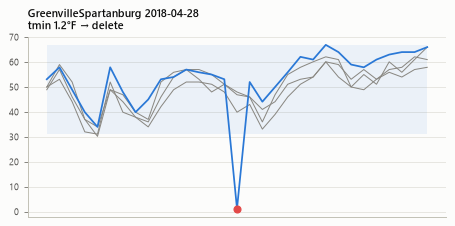

Extreme rain days (> 3x the city's 99.9th percentile), all kept:


,city_id,date,prcp,city_p999,max_neighbour_prcp_pm1day,action,name
0,USW00023044,1881-07-09,6.500,2.131,NaN,keep,ElPaso
1,USW00014860,1947-07-22,10.370,2.820,0.400,keep,Erie
2,USW00012836,1980-11-11,22.750,6.474,1.050,keep,KeyWest
3,USW00024018,1985-08-01,6.060,1.916,0.840,keep,Cheyenne


In [13]:
print("Deleted by the outlier rule:")
display(P["log"][P["log"]["rule"].str.startswith("outlier")].assign(name=lambda x: nm(x["city_id"])))
r = cand[cand["proposed_action"] == "delete"].iloc[0]
fig, ax = plt.subplots(figsize=(6, 2.6)); plot_candidate(ax, r); plt.show()
print("Extreme rain days (> 3x the city's 99.9th percentile), all kept:")
P["precip_extremes"].assign(name=lambda x: nm(x["city_id"]))

**Result:**

- **4,185 candidates; 90% are confirmed** by a nearby city: real cold outbreaks and heat waves. Kept.
- **424 isolated**, mostly before 1989 and mostly in steady climates (Gulf Coast, Florida, the Pacific coast),
  where the z-score is inflated by a small spread. 91 of them are one-day spikes.
- **1 reading is deleted:** Greenville-Spartanburg, 2018-04-28, tmin 1.2 °F between 53 °F and 52 °F, with
  neighbours normal. That is 45 °F below what the neighbours imply.
- **Kept on purpose:** Lander 2016-08-19, tmax 54 °F between 78 and 75 °F. It rained that day and Cheyenne had
  a cold front, so this is a cold rainy day and the rule correctly keeps it. Eureka 1991-08-07 (82 °F) is
  Eureka's hottest day of 1991: a real offshore-wind event.
- **Worth a human look:** some isolated readings pass every rule but still look doubtful. Examples: Ukiah
  1995-06-06, tmin 21 °F after a 30 °F night, in June, while the neighbours were normal; Escondido 2006-08-30,
  tmin 36 °F then 43 °F, in August. Each is a two-day dip, so it is not a one-day spike, and the rule keeps it.
  If you judge them errors, set `final_action = delete` in the review file.
- **Rain extremes:** 4 days above three times the city's 99.9th percentile, all physically possible; kept.

### The review file

`notebooks/Meet/qc/daily_outlier_decisions.csv` (tracked in git) lists all isolated readings with their
evidence and `proposed_action`. To overrule one, write `keep` or `delete` in `final_action` (and why in `note`),
then rerun. Reruns keep your entries. The confirmed readings are not listed: the rule keeps them.

## D5. Rebuild the yearly table from the days

**What:** recompute the annual columns from `daily`.
**Why:** (1) if the rebuild matches the published `annual_indices`, we know exactly how each target is defined,
so features built from `daily` later are consistent with the targets; (2) after cleaning, the yearly values must
be recomputed from the cleaned days.
**How:** the definitions in `mc.annual_from_daily` (e.g. `Avg Temp = (mean tmax + mean tmin) / 2`;
`cdd = Σ max(0, (tmax + tmin)/2 − 65)` over days with both values). The percentile indices (Warm/Cold
Days/Nights, Wet Days) need the original reference period, so they are taken from `annual_indices`.

In [14]:
rb = P["raw_rebuilt"].set_index(["ID", "Year"])
pub = P["annual_raw"].set_index(["ID", "Year"]).replace([np.inf, -np.inf], np.nan).reindex(rb.index)
check = {}
for c in mc.RECOMPUTED:
    a, b = rb[c], pub[c]
    both = a.notna() & b.notna()
    d = (a - b).abs()[both]
    check[c] = {"city-years compared": int(both.sum()), "value on one side only": int((a.notna() != b.notna()).sum()),
                "max |difference|": d.max(), "share within 0.01": (d <= 0.011).mean()}
pd.DataFrame(check).T

,city-years compared,value on one side only,max |difference|,share within 0.01
Miss Tmax,"28,052.000",0.000,0.000,1.000
Miss Tmin,"28,052.000",0.000,0.000,1.000
Miss Prcp,"28,052.000",0.000,0.000,1.000
Days Both,"28,052.000",0.000,0.000,1.000
Avg Tmax,"26,868.000",0.000,0.005,1.000
Avg Tmin,"26,878.000",0.000,0.005,1.000
Avg Temp,"26,859.000",0.000,0.010,1.000
ToT Prcp,"27,120.000",932.000,0.000,1.000
Max Tmax,"26,868.000",0.000,0.000,1.000
Min Tmax,"26,868.000",0.000,0.000,1.000


**Result:** every recomputed column matches the published table, to rounding (0.01 °F on `Avg Temp`).
The 932 "one side only" values for `ToT Prcp` are the published table's fake zeros: years with no rain data at all,
stored as 0 instead of empty (handled in A1). So the definitions are confirmed.

Now the same rebuild on the **cleaned** days, with the official 10-day rule. Only the city-years touched by
D2–D4 can change:

In [15]:
B = mc.build(P, mc.CUTOFF_YEAR)        # D5, D6, A3 on all data up to 2018
B["weights"] = P["weights"]
qc = B["qc"].set_index(["ID", "Year"])
ref = mc.apply_validity(P["raw_rebuilt"]).set_index(["ID", "Year"]).reindex(qc.index)
rows = []
for m, col in mc.METRIC_COL.items():
    d = (qc[col] - ref[col])
    changed = d.abs() > 1e-9
    became_nan = qc[col].isna() & ref[col].notna()
    rows.append({"metric": m, "city-years changed": int(changed.sum()), "became invalid": int(became_nan.sum()),
                 "largest change": d.abs().max(), "changed in 1989-2018": int((changed & (qc.index.get_level_values(1) >= 1989)).sum())})
pd.DataFrame(rows).set_index("metric")

,city-years changed,became invalid,largest change,changed in 1989-2018
metric,,,,
annual_avg_temp,11,0,0.194,2
total_precip_in,0,0,0.000,0
hottest_day_temp,0,0,0.000,0
cdd,1,0,6.500,0


**Result:** the cleaning changes very few yearly values: about a dozen city-years of the average temperature
(two of them in 1989–2018: Portland 1999 and Greenville-Spartanburg 2018, each by less than 0.1 °F) and one CDD
value (Montgomery 1917, where a tmax-below-tmin day was deleted). No hottest-day or rain target changes, and no year becomes invalid.

## D6. Fill missing days (inputs only)

**What:** a year that misses some days has a yearly total that **reads low**: 30 missing summer days remove
about 8% of the cooling degree days and rain.
**Why it matters:** the official rule throws away years with more than 10 missing days, so a city's training
series has holes; and years with 1–10 missing days, which are kept, still read slightly low.
**Action:** for **input** columns only, fill each missing day and recompute, for years with up to 30 missing
days. Targets keep the official rule. The hottest day is never filled: it is a single extreme day, exactly
what an estimate cannot recover.

**How a day is filled** (three candidates, tested below):

| Method | Estimate for a missing day |
|---|---|
| normal | the city's normal for that calendar day (30-year mean, 31-day smoothed) |
| normal + local anomaly | + how far the city ran above or below normal in the 15 days either side |
| normal + neighbour anomaly | + how far the nearby cities (≤ 300 mi, inverse-distance weights) ran above or below *their* normal that same day; falls back to the local anomaly, then the normal |

Rain uses ratios instead of differences (the neighbours' rain as a multiple of their normal), since rain
cannot be negative.

**Test:** take 400 complete city-years from 1989–2018, hide 10 or 30 days (as one block or scattered), fill them
with each method, and compare the yearly value with the truth. "Scale up" (multiply the observed total by
days-in-year / observed days) and "raw" (no fix) are included for comparison.

In [16]:
t0 = time.time()
sim = mc.simulate_fill(P["W_clean"], P["record"], P["weights"], n_samples=400)
print(f"simulation: {time.time() - t0:.0f} s")
order = ["raw (no fix)", "scale up to a full year", *mc.FILL_METHODS]
res = (sim.groupby(["metric", "hidden days", "pattern", "method"])["error"]
          .agg(bias="mean", mean_abs_error=lambda s: s.abs().mean()).unstack("method"))
res = res.reindex(columns=pd.MultiIndex.from_product([["bias", "mean_abs_error"], order]))
display(Markdown("Errors: °F for `Avg Temp`; % of the true yearly total for `ToT Prcp` and `cdd`."))
res.round(2)

simulation: 19 s


Errors: °F for `Avg Temp`; % of the true yearly total for `ToT Prcp` and `cdd`.

bias                                                                                  mean_abs_error                                                        \
                               raw (no fix) scale up to a full year normal normal + local anomaly normal + neighbour anomaly   raw (no fix) scale up to a full year normal normal + local anomaly   
metric   hidden days pattern                                                                                                                                                                        
Avg Temp 10          block           -0.050                  -0.050  0.000                  0.000                      0.000          0.380                   0.380  0.100                  0.100   
                     scattered        0.000                   0.000 -0.000                 -0.000                      0.000          0.120                   0.120  0.060                  0.050   
         30          block           -0.070                  -0.070  0.020                  0.020                      0.000          1.140                   1.140  0.200                  0.240   
                     scattered       -0.020                  -0.020 -0.010                 -0.010                      0.000          0.210                   0.210  0.140                  0.090   
ToT Prcp 10          block           -2.710                   0.030  0.200                 -0.030                      0.230          2.710                   2.350  2.190                  2.410   
                     scattered       -2.800                  -0.070  0.100                 -0.060                     -0.060          2.800                   2.160  2.210                  2.180   
         30          block           -8.260                  -0.050  0.510                  0.040                      0.080          8.260                   5.150  4.180                  5.100   
                     scattered       -8.250                  -0.040  0.390                  0.010                     -0.070          8.250                   3.840  3.970                  3.830   
cdd      10          block           -3.150                  -0.420 -0.590                 -0.430                     -0.060          3.150                   3.510  1.020                  0.990   
                     scattered       -2.720                   0.020 -0.490                 -0.390                      0.140          2.720                   1.200  0.930                  0.750   
         30          block           -8.370                  -0.170 -1.110                 -0.540                     -0.120          8.370                   9.980  2.670                  2.450   
                     scattered       -8.270                  -0.060 -1.540                 -1.280                      0.050          8.270                   2.220  2.150                  1.670   

                                                           
                               normal + neighbour anomaly  
metric   hidden days pattern                               
Avg Temp 10          block                          0.020  
                     scattered                      0.020  
         30          block                          0.060  
                     scattered                      0.050  
ToT Prcp 10          block                          1.420  
                     scattered                      1.550  
         30          block                          2.500  
                     scattered                      3.010  
cdd      10          block                          0.410  
                     scattered                      0.510  
         30          block                          0.800  
                     scattered                      0.840

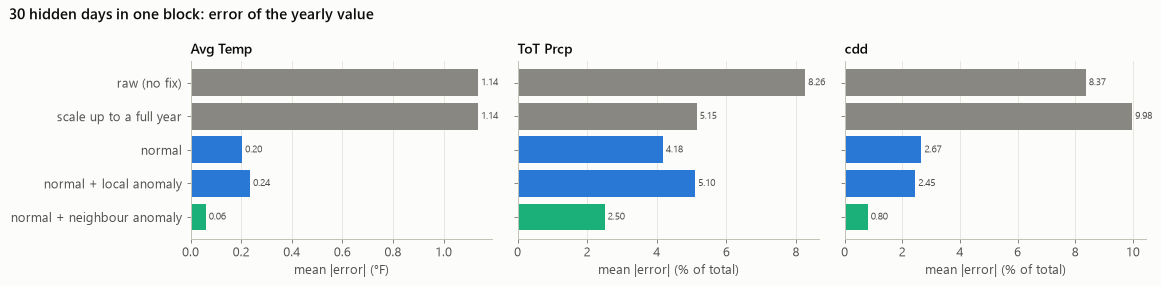

In [17]:
blk = sim[(sim["hidden days"] == 30) & (sim["pattern"] == "block")]
mae = blk.groupby(["metric", "method"])["error"].apply(lambda s: s.abs().mean()).unstack().reindex(columns=order)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (metric, unit) in zip(axs, [("Avg Temp", "°F"), ("ToT Prcp", "% of total"), ("cdd", "% of total")]):
    v = mae.loc[metric]
    ax.barh(range(len(v)), v.values, color=[MUTED, MUTED, SERIES[0], SERIES[0], SERIES[2]])
    ax.set_yticks(range(len(v)), v.index if metric == "Avg Temp" else [""] * len(v))
    ax.invert_yaxis(); ax.set_xlabel(f"mean |error| ({unit})"); ax.set_title(metric); ax.grid(axis="y", visible=False)
    for i, x in enumerate(v.values):
        ax.text(x, i, f" {x:.2f}", va="center", fontsize=8, color=INK2)
fig.suptitle("30 hidden days in one block: error of the yearly value", x=0.01, ha="left", fontweight="semibold")
plt.tight_layout(); plt.show()

In [18]:
# What filling recovers in the 1989-2018 window (city-years with an input value)
F = B["filled"].set_index(["ID", "Year"])
win = qc.index.get_level_values(1) >= 1989
rows = []
for col, m in [("Avg Temp", "annual_avg_temp"), ("ToT Prcp", "total_precip_in"), ("cdd", "cdd")]:
    rows.append({"metric": m, "valid with the 10-day rule": int(qc.loc[win, col].notna().sum()),
                 "valid after filling (<= 30 missing days)": int(F.reindex(qc.index).loc[win, col].notna().sum())})
t = pd.DataFrame(rows).set_index("metric")
t["recovered"] = t.iloc[:, 1] - t.iloc[:, 0]
t

,valid with the 10-day rule,valid after filling (<= 30 missing days),recovered
metric,,,
annual_avg_temp,5996,6095,99
total_precip_in,6024,6070,46
cdd,5996,6095,99


**Result:**

- **Raw sums read low:** about −2.7% for 10 missing days and −8.3% for 30, for both rain and CDD.
- **Scaling up removes the bias on average but is unreliable for blocks:** for CDD with 30 days missing in one
  block, it is off by 10% on average (a missing July block is not like a missing January block).
- **"Normal + neighbour anomaly" is clearly best on every test:**
  - Mean error: 0.06 °F for the yearly temperature, about 0.8% for CDD and 2.5–3% for rain (30 hidden days).
  - That is 2–4 times smaller than the normal alone.
  - Bias stays under 0.25%.
  - It is the method the pipeline uses (`mc.FILL_METHOD`).
- **Recovered city-years in 1989–2018:** about 100 for temperature and CDD, and 46 for rain.

# Part 2 · `annual_indices`

## A1. Sentinels and validity

**What:** two kinds of placeholder values, and partial years.

- **±∞ sentinels:** a year with no data at all stores ±∞ for its extremes (e.g. `Max Tmax`).
- **Fake zeros:** the same year stores 0 for its totals and percentages (`ToT Prcp` = 0 with every rain day missing).
- **Partial years:** a year missing many days reads low (D6).

**Why:** a fake zero is not "no rain"; it would pull every average toward zero.
**Action:** ±∞ → empty; then each column → empty when its year misses more than 10 days of the variable it is
computed from. That is the official rule for the four targets, and the same rule for the other columns
(`mc.MISS_RULE`). Because D5 recomputes the yearly values from cleaned days, fake zeros cannot occur in the
recomputed columns: a year with no data sums to empty, not 0.

In [19]:
a = P["annual_raw"]
cols = list(mc.MISS_RULE)
inf = a[cols].isin([np.inf, -np.inf]).sum()
fake0 = pd.Series({c: int(((a[c] == 0) & (a[mc.MISS_RULE[c]].min(axis=1) >= pd.to_datetime(a["Year"].astype(str) + "-12-31").dt.day_of_year)).sum())
                   for c in cols})
valid = mc.apply_validity(a)
t = pd.DataFrame({"±inf": inf, "fake zeros (no data that year)": fake0,
                  "non-empty before": a[cols].replace([np.inf, -np.inf], np.nan).notna().sum(),
                  "valid after the rule": valid[cols].notna().sum()})
t["removed"] = t["non-empty before"] - t["valid after the rule"]
t

,±inf,fake zeros (no data that year),non-empty before,valid after the rule,removed
Avg Tmax,0,0,26868,24868,2000
Min Tmax,1184,0,26868,24868,2000
Warm Days,0,1184,28052,24868,3184
Cold Days,0,1184,28052,24868,3184
Avg Tmin,0,0,26878,24923,1955
Max Tmin,1174,0,26878,24923,1955
Min Tmin,1174,0,26878,24923,1955
Warm Nights,0,1174,28052,24923,3129
Cold Nights,0,1174,28052,24923,3129
Max 1-day P,932,0,27120,24858,2262


## A2. Detached record fragments

**What:** a few cities have early years from an old station, then decades with no data at all, then the modern
record.
**Why:** those early years are from a different site, separated by more than 30 empty years. They cannot inform a
2019–2025 forecast, and they distort any statistic computed over "all history" (a long-term mean or trend).
**Action:** delete the years before the gap (daily and annual); keep the block that reaches 2018.

In [20]:
fr = P["fragments"].assign(name=lambda x: nm(x["city_id"]))
fr[["name", "city_id", "first_dropped", "last_dropped", "years_with_data_dropped", "record_resumes"]]

,name,city_id,first_dropped,last_dropped,years_with_data_dropped,record_resumes
0,Asheville,USW00003812,1870,1876,7,1964
1,Huntsville,USW00003856,1895,1958,64,2018
2,Wheeling,USW00014894,1879,1953,62,1998
3,Akron,USW00014895,1888,1952,65,1999
4,SiouxCity,USW00014943,1890,1895,6,1996
5,Pueblo,USW00093058,1889,1892,4,1940
6,Vancouver,USW00094298,1856,1856,1,1891


**Result:** 7 cities.

- **Sioux City:** loses its 1890–1895 years from the old station.
- **Larger cuts:** Huntsville (1895–1958, then only 2018 has data), Wheeling (1879–1953, resumes 1998) and
  Akron (1888–1952, resumes 1999).
- **Smaller cuts:** Pueblo, Asheville and Vancouver lose a few years.

Apart from Huntsville's 1957–58 (a city that is not scored), none of the dropped years falls inside a
30-year window ending in 1986 or later, so the backtests and the forecast are unaffected. The cut affects only
long-history statistics. Huntsville stays with one year and is not scored
(the challenge needs 10 valid years in 1989–2018).

## A3. Station changes (inputs only)

**What:** a city's record is built from several stations (e.g. downtown, then the airport). When the station
changes, the record can jump with no change in climate.
**Why:** a jump looks like a trend. A trend line, or a 10-year mean that spans the change, carries the jump into
the forecast. The 2019–2025 answers come from today's station, so history should be on today's station's level.

**How (for Avg Tmax and Avg Tmin separately):**

1. Take the city's yearly values minus a reference built from its neighbours (≤ 300 mi, inverse-distance
   weights, each neighbour as its departure from its own mean over the window). Shared weather cancels in this
   difference, so a shift in the difference is the station.
2. Compare the 10 years after the change with the 10 years before (the change year itself is left out unless
   the change is on 1 January; windows stop at the city's other changes).
3. Step = mean after − mean before. Adopt it if |t| ≥ 2, |step| ≥ 0.25 °F and both sides have ≥ 5 valid years.
4. Shift all daily tmax / tmin before the change by the step, so old readings sit on today's station level;
   multiple changes add up. Then recompute the yearly values (so CDD and the hottest day are adjusted too).
5. Repeat once with neighbours that were themselves adjusted in the first pass (a neighbour's own jump
   would otherwise leak into the reference).

Rain is not adjusted: a station move changes rain much less systematically, and the year-to-year noise is too
large to measure a step reliably.

          changes  testable  adopted
var                                 
Avg Tmax      251       191      138
Avg Tmin      251       191      145


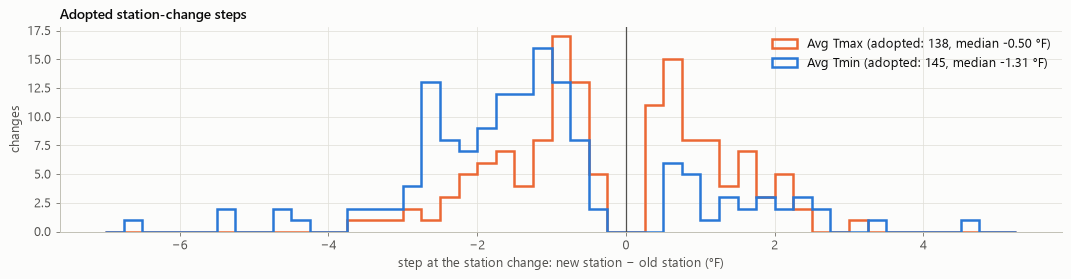

,name,var,change_date,step,t,n_before,n_after
474,McCook,Avg Tmin,1989-09-10,1.950,6.304,8,5
223,McCook,Avg Tmax,1989-09-10,-0.848,-4.169,9,6
110,MiddletownHarrisburg,Avg Tmax,1991-10-01,1.125,3.721,10,10
159,Omaha,Avg Tmax,1994-01-01,1.586,8.578,10,10
410,Omaha,Avg Tmin,1994-01-01,-0.715,-4.533,10,10
8,Denver,Avg Tmax,1995-03-01,-1.170,-4.226,10,10
259,Denver,Avg Tmin,1995-03-01,-0.959,-4.782,10,10
11,Yuma,Avg Tmax,1995-12-01,-0.578,-3.134,10,10
262,Yuma,Avg Tmin,1995-12-01,0.608,3.081,10,10
229,Vancouver,Avg Tmax,1996-09-15,0.364,2.023,9,10


In [21]:
st = B["steps"].assign(name=lambda x: nm(x["city_id"]))
print(st.groupby("var").agg(changes=("step", "size"), testable=("step", "count"), adopted=("applied", "sum")).to_string())
fig, ax = plt.subplots(figsize=(12, 3.2))
bins = np.arange(-7, 5.5, 0.25)
for i, (var, col) in enumerate([("Avg Tmax", SERIES[1]), ("Avg Tmin", SERIES[0])]):
    s = st[(st["var"] == var) & st["applied"]]["step"]
    ax.hist(s, bins=bins, histtype="step", lw=2, color=col, label=f"{var} (adopted: {len(s)}, median {s.median():+.2f} °F)")
ax.axvline(0, color=INK2, lw=1)
ax.set_xlabel("step at the station change: new station − old station (°F)"); ax.set_ylabel("changes")
ax.set_title("Adopted station-change steps"); ax.legend(); plt.tight_layout(); plt.show()
st[st["applied"] & (st["year"] >= 1989)].sort_values("change_date")[["name", "var", "change_date", "step", "t", "n_before", "n_after"]]

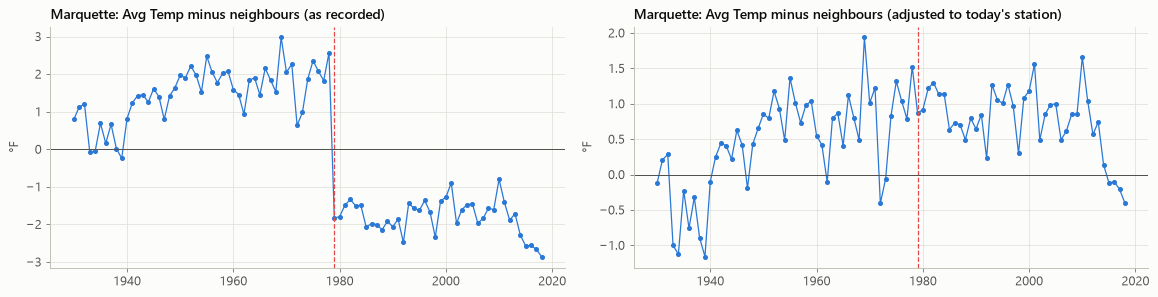

Adopted steps for Marquette:


,var,change_date,step,t,applied
242,Avg Tmax,1979-01-01,-0.983,-4.413,True
493,Avg Tmin,1979-01-01,-6.511,-19.471,True


In [22]:
# Example: the city with the largest adopted step since 1950. Its temperature minus its neighbours' reference, before/after.
ex = st[st["applied"] & (st["year"] >= 1950)].assign(a=lambda x: x["step"].abs()).sort_values("a").iloc[-1]
city = ex["city_id"]
hom = B["homog"].set_index(["ID", "Year"])
fig, axs = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, (label, tab) in zip(axs, [("as recorded", qc), ("adjusted to today's station", hom)]):
    T = tab["Avg Temp"].unstack("ID")
    w = P["weights"].loc[city]
    nbs = w[w > 0].index
    ref = (T[nbs] - T[nbs].mean()).mul(w[nbs]).sum(axis=1) / T[nbs].notna().mul(w[nbs]).sum(axis=1)
    d = (T[city] - T[city].mean() - ref).loc[1930:2018]
    ax.plot(d.index, d.values, color=SERIES[0], marker="o", ms=3, lw=1)
    for y in st[(st["city_id"] == city) & (st["var"] == "Avg Tmax")]["year"]:
        ax.axvline(y, color=DELETE, lw=1, ls="--")
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_title(f"{ex['name']}: Avg Temp minus neighbours ({label})"); ax.set_ylabel("°F")
plt.tight_layout(); plt.show()
print(f"Adopted steps for {ex['name']}:")
st[(st["city_id"] == city)][["var", "change_date", "step", "t", "applied"]]

**Result:** 382 station changes can be tested (some cities have no neighbour within 300 miles, or too few
valid years around a change). For 283 of them a step is adopted. Most steps are negative: new stations, often
airports, read cooler than the old downtown sites, especially at night (tmin). A typical adopted step is
about 1 °F. The adjusted series varies around a flat line where the recorded one has jumps. Whether this
improves a forecast is tested in section E.

## A4. Empty years (inputs only)

**What:** years that are still empty after D6 (more than 30 missing days, or no data at all).
**Why:** a 10-year mean with 3 empty years is really a 7-year mean of different years, and a trend line has
gaps. You asked not to use placeholder numbers, so no constant goes in. Instead the value comes from evidence:
what the nearby cities measured that year.
**How:** for a missing year y and each neighbour n (≤ 300 mi) with a value in y:
`estimate = value of n in y + mean(city − n)` over the 15 common valid years closest to y. Average these over
the neighbours with inverse-distance weights. At least 2 neighbours are needed, and nothing is filled before a
city's record starts.
**Test:** hide known years of 1989–2018 one at a time and fill them; compare with two simple fills.

In [23]:
rows = {}
for m, col in mc.METRIC_COL.items():
    T = mc._wide(B["qc"], col, mc.CUTOFF_YEAR)
    rows[m] = mc.leave_one_out_infill(T, P["weights"], n_samples=800).abs().mean()
loo = pd.DataFrame(rows).T
loo["error cut vs city mean"] = 1 - loo["neighbour infill"] / loo["city mean, 15 years either side"]
display(Markdown("Mean absolute error of the filled value, hiding 800 known city-years per metric (units of the metric):"))
display(loo.style.format({c: "{:.2f}" for c in loo.columns[:-1]} | {"error cut vs city mean": "{:.0%}"}))
V = mc.variants(B)
win = list(range(1989, 2019))
pd.DataFrame({m: {"valid (10-day rule)": int(V["qc"][m][win].notna().sum().sum()),
                  "after neighbour infill": int(V["qc+nbfill"][m][win].notna().sum().sum())} for m in mc.METRIC_COL}).T

Mean absolute error of the filled value, hiding 800 known city-years per metric (units of the metric):

,"city mean, 15 years either side",previous valid year,neighbour infill,error cut vs city mean
annual_avg_temp,1.13,1.38,0.39,65%
total_precip_in,5.67,7.63,3.74,34%
hottest_day_temp,2.53,3.33,1.42,44%
cdd,159.09,207.11,68.76,57%


,valid (10-day rule),after neighbour infill
annual_avg_temp,5996,6241
total_precip_in,6024,6242
hottest_day_temp,5996,6241
cdd,5996,6241


**Result:** compared with the city's own mean, neighbour infill cuts the error by about 65% for temperature,
57% for CDD, 44% for the hottest day and 34% for rain. Copying the previous year is the worst option. In
1989–2018 it fills about 220–245 city-years per metric. Filled values are always flagged
(`<metric>_input_source = "neighbour infill"`) and never used as targets.

# Part 3 · Does it help a forecast?

## E. Backtest of the input variants

Cleaning is worth keeping only if it helps predict the **official** numbers. Test:

- **Origins:** 1986, 1994, 2002, 2010. For each origin O, rebuild every input variant from data up to O only:
  normals, station steps and infill all stop at O, and a change after O is not used. Forecast O+1 … O+8.
- **Scoring:** like the leaderboard, against the official values in `data/annual_valid.csv`, on the city-years
  the challenge would score, with skill relative to the official 30-year average.
- **Forecasters:** the team's four (30-year average, 10-year mean, 30-year trend, blend). The decision uses the
  one `code/combo_model.py` currently uses for each metric.
- **Variants:** `qc` (cleaned days, official rule), `+fill` (D6), `+homog` (A3), `+nbfill` (A4), and their
  combinations; `official` is the published data as is.

**Selection rule:**

- A variant replaces plain `qc` for a metric only if its mean skill is at least **0.002 higher** (0.2 leaderboard
  points) and it beats `qc` in **at least 3 of the 4** origins.
- Otherwise `qc` stays.
- The result goes into `<metric>_input`.

Only cleaning decisions made once on the whole record (the outlier and stuck-run rules) are not rebuilt per
origin. They touch a handful of readings, none of them in a test window that would matter.

In [24]:
t0 = time.time()
bt = mc.backtest(P, verbose=False)
print(f"backtest: {time.time() - t0:.0f} s")
combo = bt[bt["model"] == bt["metric"].map(cm.METHOD)]
order_v = ["official", "qc", "qc+fill", "qc+homog", "qc+nbfill", "qc+fill+homog", "qc+fill+homog+nbfill"]
display(Markdown("**Mean skill over the 4 origins, current forecaster per metric** (" +
                 ", ".join(f"{m}: {cm.METHOD[m]}" for m in mc.METRIC_COL) + ")"))
display(combo.pivot_table(index="variant", columns="metric", values="skill").reindex(order_v).style.format("{:.4f}"))
score = combo.groupby(["variant", "origin"])["skill"].mean().clip(lower=0).mul(100).unstack()
score["mean"] = score.mean(axis=1)
display(Markdown("**Leaderboard-style score per origin** (100 × mean skill over the 4 metrics):"))
score.reindex(order_v).round(2)

backtest: 71 s


**Mean skill over the 4 origins, current forecaster per metric** (annual_avg_temp: blend, total_precip_in: average, hottest_day_temp: average, cdd: blend)

metric,annual_avg_temp,cdd,hottest_day_temp,total_precip_in
variant,,,,
official,0.0964,0.0778,0.0000,0.0000
qc,0.0964,0.0778,0.0000,0.0000
qc+fill,0.0953,0.0785,0.0000,-0.0009
qc+homog,0.0997,0.0803,-0.0012,0.0000
qc+nbfill,0.0954,0.0788,-0.0001,0.0003
qc+fill+homog,0.0987,0.0810,-0.0012,-0.0009
qc+fill+homog+nbfill,0.0985,0.0825,-0.0013,-0.0010


**Leaderboard-style score per origin** (100 × mean skill over the 4 metrics):

origin,1986,1994,2002,2010,mean
variant,,,,,
official,1.550,3.840,4.650,7.380,4.360
qc,1.550,3.840,4.650,7.380,4.360
qc+fill,1.310,3.760,4.690,7.530,4.320
qc+homog,1.810,3.940,4.610,7.520,4.470
qc+nbfill,1.690,3.920,4.660,7.170,4.360
qc+fill+homog,1.580,3.870,4.650,7.660,4.440
qc+fill+homog+nbfill,1.800,3.980,4.560,7.540,4.470


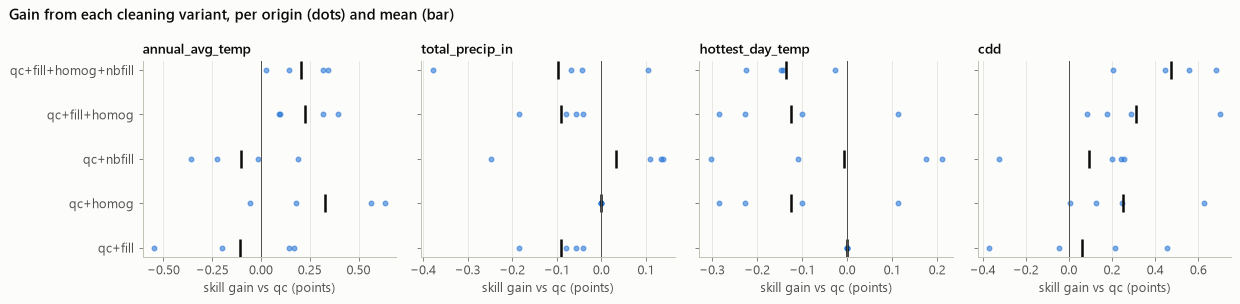

In [25]:
gain = (combo.pivot_table(index=["metric", "origin"], columns="variant", values="skill")
        .sub(combo[combo["variant"] == "qc"].set_index(["metric", "origin"])["skill"], axis=0) * 100)
fig, axs = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
vs = ["qc+fill", "qc+homog", "qc+nbfill", "qc+fill+homog", "qc+fill+homog+nbfill"]
for ax, m in zip(axs, mc.METRIC_COL):
    g = gain.loc[m, vs]
    for j, v in enumerate(vs):
        ax.scatter(g[v].values, [j] * len(g), color=SERIES[0], s=14, alpha=0.6)
        ax.scatter([g[v].mean()], [j], color=INK, marker="|", s=200)
    ax.axvline(0, color=INK2, lw=0.8)
    ax.set_yticks(range(len(vs)), vs); ax.set_title(m); ax.set_xlabel("skill gain vs qc (points)")
    ax.grid(axis="y", visible=False)
fig.suptitle("Gain from each cleaning variant, per origin (dots) and mean (bar)", x=0.01, ha="left", fontweight="semibold")
plt.tight_layout(); plt.show()

In [26]:
choice = mc.choose_inputs(bt)
display(choice)
assert choice["chosen"].to_dict() == mc.INPUT_RECIPE, (
    "The backtest now picks different inputs than mc.INPUT_RECIPE: update the constant in meet_cleaning.py")
print("mc.INPUT_RECIPE matches the backtest choice:", mc.INPUT_RECIPE)

,chosen,mean skill qc,mean skill chosen,gain,origins won
metric,,,,,
annual_avg_temp,qc+homog,0.096,0.100,0.003,3
total_precip_in,qc,0.000,0.000,0.000,0
hottest_day_temp,qc,0.000,0.000,0.000,0
cdd,qc+fill+homog+nbfill,0.078,0.083,0.005,4


mc.INPUT_RECIPE matches the backtest choice: {'annual_avg_temp': 'qc+homog', 'total_precip_in': 'qc', 'hottest_day_temp': 'qc', 'cdd': 'qc+fill+homog+nbfill'}


In [27]:
# Side finding: station adjustment helps a trend line much more than a flat mean
t = bt[bt["metric"].isin(["annual_avg_temp", "cdd"]) & bt["variant"].isin(["qc", "qc+homog", "qc+fill+homog+nbfill"])]
t.pivot_table(index=["metric", "model"], columns="variant", values="skill").style.format("{:.4f}")

**Result: honest and small.**

- **Average temperature:** station adjustment (`qc+homog`) raises mean skill from 0.096 to 0.100, better in
  3 of 4 origins and equal in the fourth.
- **CDD:** the full pipeline (fill + adjust + infill) raises it from 0.078 to 0.083, better in all 4 origins.
- **Rain and the hottest day:** no variant helps. They stay on `qc`.
- **Leaderboard-style score:** about +0.1 points. Cleaning matters more for the
  quality of what a model learns from than for a flat-mean forecast.
- **Side finding:** for a **trend line** the station adjustment is worth much more (temperature trend skill
  0.074 → 0.082, CDD 0.055 → 0.060), because jumps are exactly what fakes a trend. Any trend-based or ML model
  later should use the adjusted inputs.
- **Caveat:** the forecast with the plain 30-year average gets slightly *worse* with adjustment. Step
  estimates carry noise, and a flat mean gains nothing from removing a jump inside its window.
- **This is why each variant is a separate column:** a model can choose.

# Part 4 · Outputs

## F. The processed files

Written to `data/processed/meet/` (git-ignored; rebuilt by this notebook or by `uv run python notebooks/Meet/meet_cleaning.py`).

In [28]:
annual_clean = mc.assemble_annual(P, B, V)
daily_clean = mc.assemble_daily(B)
mc.OUT_DIR.mkdir(parents=True, exist_ok=True)
annual_clean.to_parquet(mc.OUT_DIR / "annual_clean.parquet", index=False)
daily_clean.to_parquet(mc.OUT_DIR / "daily_clean.parquet", index=False)
P["log"].to_csv(mc.OUT_DIR / "qc_log.csv", index=False)
B["steps"].to_csv(mc.OUT_DIR / "homog_steps.csv", index=False)
for f in ["annual_clean.parquet", "daily_clean.parquet", "qc_log.csv", "homog_steps.csv"]:
    p = mc.OUT_DIR / f
    print(f"{p.relative_to(ROOT)}  {p.stat().st_size / 1e6:6.1f} MB")
print("annual_clean", annual_clean.shape, " daily_clean", daily_clean.shape)

data\processed\meet\annual_clean.parquet     3.0 MB
data\processed\meet\daily_clean.parquet    93.7 MB
data\processed\meet\qc_log.csv     0.0 MB
data\processed\meet\homog_steps.csv     0.0 MB
annual_clean (27413, 52)  daily_clean (10012366, 10)


In [29]:
# Sanity checks: data rule, and targets = official values except where cleaning changed something
mc.assert_no_post_cutoff(annual_clean, "year", "annual_clean")
off = load_valid_annual().set_index(["city_id", "year"])
mine = annual_clean.set_index(["city_id", "year"])
dropped = ~off.index.isin(mine.index)                                    # A2 fragments (and the empty years after them)
touched = (mine[["n_deleted_tmax", "n_deleted_tmin", "n_deleted_prcp"]].sum(axis=1)
           .reindex(off.index).fillna(0) > 0)                            # years with readings deleted in D2-D4
rows = []
for m in mc.METRIC_COL:
    a, b = mine[m].reindex(off.index), off[m]
    same = ((a - b).abs() <= 0.011) | (a.isna() & b.isna())             # published values are rounded to 0.01
    diff = ~same
    rows.append({"metric": m, "differ from data/annual_valid.csv": int(diff.sum()),
                 "in dropped fragments": int((diff & dropped).sum()),
                 "in years with deleted readings": int((diff & ~dropped & touched).sum()),
                 "unexplained": int((diff & ~dropped & ~touched).sum())})
chk = pd.DataFrame(rows).set_index("metric")
assert (chk["unexplained"] == 0).all(), "targets differ from the official values for an unexplained reason"
chk

,differ from data/annual_valid.csv,in dropped fragments,in years with deleted readings,unexplained
metric,,,,
annual_avg_temp,162,153,9,0
total_precip_in,124,124,0,0
hottest_day_temp,153,153,0,0
cdd,154,153,1,0


In [30]:
DICT = [
    ("city_id, name, lat, lon, year", "keys and location"),
    ("days_in_year", "days of that year inside the record"),
    ("miss_tmax, miss_tmin, miss_prcp, days_both", "missing days after cleaning; days with both temperatures"),
    ("annual_avg_temp, total_precip_in, hottest_day_temp, cdd", "TARGETS: official definition and 10-day rule, from cleaned days. Empty when invalid. Never filled or adjusted."),
    ("avg_tmax, avg_tmin, min_tmax, max_tmin, min_tmin, max_1day_p, max_5day_p", "other yearly indices, from cleaned days, 10-day rule"),
    ("warm_days, warm_nights, cold_days, cold_nights, wet_days", "percentile indices from annual_indices, 10-day rule"),
    ("station_segment, station_changes", "station in use on 1 Jan; new stations that year (coverage_and_stations)"),
    ("n_deleted_tmax / _tmin / _prcp", "readings deleted by D2-D4 that year"),
    ("<metric>_filled", "INPUT: from filled days, years with <= 30 missing days (not for the hottest day)"),
    ("<metric>_homog", "INPUT: from station-adjusted days, 10-day rule (temperature metrics and CDD)"),
    ("<metric>_full", "INPUT: filled + adjusted + neighbour infill of empty years"),
    ("<metric>_input", "INPUT chosen by the backtest (mc.INPUT_RECIPE): use this as the default model input"),
    ("<metric>_input_source", "measured / filled days / neighbour infill: how <metric>_input was obtained"),
    ("n_filled_tmax / _tmin / _prcp", "days filled by D6 that year"),
]
display(pd.DataFrame(DICT, columns=["columns", "meaning"]).style.hide(axis="index"))
display(Markdown("**daily_clean.parquet:** `tmax, tmin, prcp` cleaned (deleted readings empty); `*_filled` the same with "
                 "missing days filled (D6, on the recorded station's level); `tmax_offset, tmin_offset` the station "
                 "adjustment to add (A3). Only days inside each kept record."))
annual_clean.query("year == 2018").head(3).T

columns,meaning
"city_id, name, lat, lon, year",keys and location
days_in_year,days of that year inside the record
"miss_tmax, miss_tmin, miss_prcp, days_both",missing days after cleaning; days with both temperatures
"annual_avg_temp, total_precip_in, hottest_day_temp, cdd","TARGETS: official definition and 10-day rule, from cleaned days. Empty when invalid. Never filled or adjusted."
"avg_tmax, avg_tmin, min_tmax, max_tmin, min_tmin, max_1day_p, max_5day_p","other yearly indices, from cleaned days, 10-day rule"
"warm_days, warm_nights, cold_days, cold_nights, wet_days","percentile indices from annual_indices, 10-day rule"
"station_segment, station_changes",station in use on 1 Jan; new stations that year (coverage_and_stations)
n_deleted_tmax / _tmin / _prcp,readings deleted by D2-D4 that year
_filled,"INPUT: from filled days, years with <= 30 missing days (not for the hottest day)"
_homog,"INPUT: from station-adjusted days, 10-day rule (temperature metrics and CDD)"


**daily_clean.parquet:** `tmax, tmin, prcp` cleaned (deleted readings empty); `*_filled` the same with missing days filled (D6, on the recorded station's level); `tmax_offset, tmin_offset` the station adjustment to add (A3). Only days inside each kept record.

,124,249,375
city_id,USC00042863,USC00166584,USC00280734
name,Escondido,Natchitoches,Belvidere
lat,33.121,31.814,40.829
lon,-117.090,-93.086,-75.083
year,2018,2018,2018
days_in_year,365,365,365
miss_tmax,0,0,13
miss_tmin,0,0,8
miss_prcp,0,0,8
days_both,365,365,352


## Summary

| Step | What was found | What was done |
|---|---|---|
| D1 Structure | Clean keys and calendars; 416k empty days | Nothing to fix |
| D2 Impossible | 9 days with tmax < tmin; nothing beyond physical limits | 18 temperatures deleted |
| D3 Stuck sensors | 402 runs of ≥ 7 identical values, almost all steady real weather | 5 runs deleted (44 readings, 1902–1931) |
| D3 Repeated rain | 1,566 runs, mostly drizzle; multi-day totals spread evenly | Kept (yearly totals unchanged) |
| D4 Outliers | 4,185 candidates, 90% confirmed by neighbours; coastal heat days are real | 1 reading deleted (Greenville 2018 tmin 1.2 °F); 424 isolated listed for review |
| D5 Rebuild | Published yearly table reproduced to rounding | Targets recomputed from cleaned days, official rule |
| D6 Fill days | Normal + neighbour anomaly: 2–4× more accurate than the alternatives | Input columns; ~100 temperature and 46 rain city-years recovered in 1989–2018 |
| A1 Sentinels | ±∞ and 932 fake-zero rain years | Empty; 10-day rule on every column |
| A2 Fragments | 7 cities with detached early years | Deleted |
| A3 Station changes | 283 adopted steps, typically about 1 °F, mostly cooler | Input columns |
| A4 Empty years | Neighbour infill: 34–65% less error than the city mean | Input columns, flagged |
| E Backtest | Small but consistent gains for temperature and CDD; none for rain and the hottest day | `<metric>_input` follows the backtest |

**For you to review before modelling:**

1. The isolated outliers in `notebooks/Meet/qc/daily_outlier_decisions.csv` (and the PNG pages in
   `data/processed/meet/outlier_plots/`). Overrule any `proposed_action` in `final_action`.
2. The thresholds at the top of `meet_cleaning.py`, especially `RESID_F_DELETE` (25 °F),
   `STUCK_NEIGHBOUR_SD` (5 °F) and `HOMOG_MIN_T` (2).
3. Whether the station adjustment should feed the trend-based models (the backtest says it helps them most).

**Next:** feature engineering on `annual_clean.parquet` and `daily_clean.parquet` (seasonal means, heat-wave counts,
regional anomalies), always using `<metric>_input` columns as inputs and the plain metric columns as targets.